# Task 3.4 — Batch Image Preprocessor

This offline demo uses clearly labeled synthetic fixtures to verify behavior, not to estimate photo-classification accuracy. An optional folder cell processes real images.


In [1]:
from dataclasses import asdict
from pathlib import Path
import json

import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

from brandlens.preprocessing.image_io import load_image
from brandlens.preprocessing.photo_filter import FilterSettings
from brandlens.preprocessing.preprocessor import preprocess_batch
from brandlens.preprocessing.standardization import StandardizationSettings

filter_settings = FilterSettings()
standardization_settings = StandardizationSettings(max_size=(256, 256))
print(asdict(filter_settings))
print(asdict(standardization_settings))


{'min_short_side': 64, 'max_aspect_ratio': 5.0}
{'max_size': (256, 256), 'background': (255, 255, 255)}


In [2]:
scene = Image.new("RGB", (640, 400), (120, 180, 230))
draw = ImageDraw.Draw(scene)
draw.rectangle((0, 250, 640, 400), fill=(60, 140, 70))
draw.ellipse((440, 40, 520, 120), fill=(255, 220, 80))
transparent = Image.new("RGBA", (400, 200), (0, 0, 0, 0))
ImageDraw.Draw(transparent).rectangle((40, 40, 200, 160), fill=(220, 40, 80, 128))
rotated = scene.copy()
rotated.getexif()[274] = 6
rotated.info["exif"] = rotated.getexif().tobytes()
bad_profile = scene.copy()
bad_profile.info["icc_profile"] = b"invalid"
images = {
    "synthetic_scene": scene,
    "small_asset": Image.new("RGB", (32, 32), "blue"),
    "elongated_asset": Image.new("RGB", (800, 100), "orange"),
    "grayscale": scene.convert("L"),
    "transparent": transparent,
    "rotated": rotated,
    "bad_profile": bad_profile,
    "valid_after_error": scene.copy(),
}
original_pixels = {key: image.tobytes() for key, image in images.items()}
result = preprocess_batch(images, filter_settings, standardization_settings)
print({status: len(items) for status, items in result.items()})
print("Excluded:", result["excluded"])
print("Errors:", result["errors"])

assert len(result["accepted"]) == 5
assert len(result["excluded"]) == 2
assert len(result["errors"]) == 1
assert all(image.tobytes() == original_pixels[key] for key, image in images.items())
for image in result["accepted"].values():
    assert image.mode == "RGB"
    assert max(image.size) <= 256
    assert "icc_profile" in image.info
print("Mixed-batch acceptance checks passed.")


{'accepted': 5, 'excluded': 2, 'errors': 1}
Excluded: {'small_asset': 'Rejected by geometry filter.', 'elongated_asset': 'Rejected by geometry filter.'}
Errors: {'bad_profile': 'ValueError: Could not convert the embedded color profile to sRGB.'}
Mixed-batch acceptance checks passed.


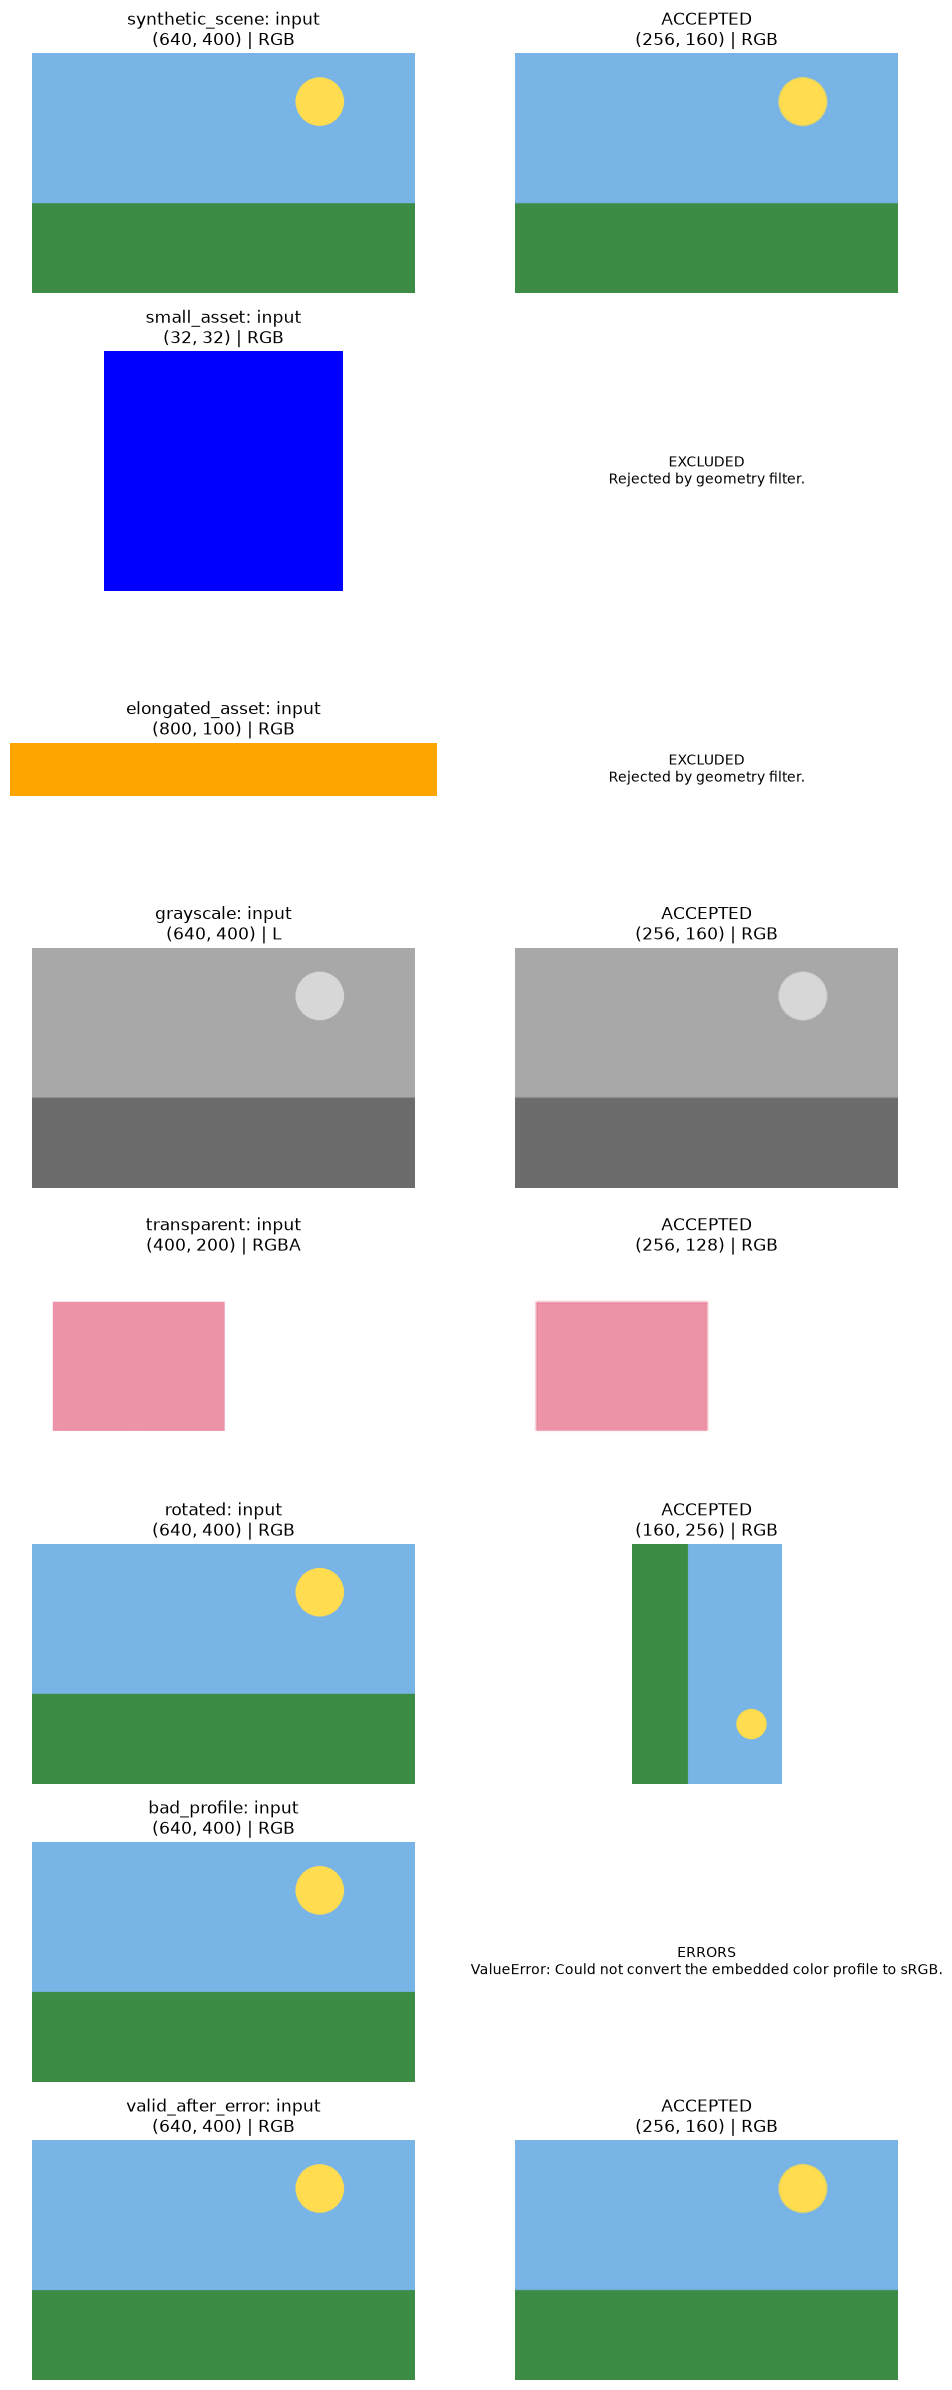

In [3]:
fig, axes = plt.subplots(len(images), 2, figsize=(10, 3 * len(images)), squeeze=False)
for row, (image_id, original) in zip(axes, images.items()):
    row[0].imshow(original.convert("RGBA"))
    row[0].set_title(f"{image_id}: input\n{original.size} | {original.mode}")
    if image_id in result["accepted"]:
        processed = result["accepted"][image_id]
        row[1].imshow(processed)
        row[1].set_title(f"ACCEPTED\n{processed.size} | {processed.mode}")
    else:
        status = "excluded" if image_id in result["excluded"] else "errors"
        row[1].text(0.5, 0.5, f"{status.upper()}\n{result[status][image_id]}",
                    ha="center", va="center", wrap=True, transform=row[1].transAxes)
    for ax in row:
        ax.axis("off")
plt.tight_layout()
plt.show()


## Optional: real image folder

Set `image_folder` to a folder. Immediate files are attempted through the existing loader; subfolders are skipped. Loading failures are reported separately because the batch interface accepts already-loaded images. File names serve as unique IDs in this flat folder.


In [4]:
image_folder = None  # Example: Path(r"F:\images")
real_result = None
if image_folder is not None:
    folder = Path(image_folder)
    if not folder.is_dir():
        raise ValueError(f"Not a directory: {folder}")
    real_images, load_errors = {}, {}
    for path in sorted(folder.iterdir()):
        if not path.is_file():
            continue
        try:
            real_images[path.name] = load_image(path)
        except (OSError, ValueError) as error:
            load_errors[path.name] = f"{type(error).__name__}: {error}"
    try:
        real_result = preprocess_batch(real_images, filter_settings, standardization_settings)
    finally:
        for image in real_images.values():
            image.close()
    print("Batch:", {status: len(items) for status, items in real_result.items()})
    print("Loading errors:", load_errors)
    print("Excluded:", real_result["excluded"])
    print("Processing errors:", real_result["errors"])


## Optional: save demo evidence

Set `save_evidence=True` to create a new timestamped output folder containing accepted PNGs and a JSON summary. These are outputs from the synthetic demonstration. No input images are overwritten. The summary excludes Pillow objects so it can be serialized.


In [5]:
save_evidence = False
if save_evidence:
    from datetime import datetime

    output_dir = Path("outputs") / datetime.now().strftime("preprocessor_%Y%m%d_%H%M%S_%f")
    output_dir.mkdir(parents=True, exist_ok=False)
    accepted_summary = {}
    for image_id, image in result["accepted"].items():
        filename = f"{image_id}.png"
        image.save(output_dir / filename, icc_profile=image.info["icc_profile"])
        accepted_summary[image_id] = {"file": filename, "size": image.size, "mode": image.mode}
    summary = {
        "filter_settings": asdict(filter_settings),
        "standardization_settings": asdict(standardization_settings),
        "accepted": accepted_summary,
        "excluded": result["excluded"],
        "errors": result["errors"],
    }
    (output_dir / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    print("Evidence saved:", output_dir.resolve())


## Interpretation

Acceptance here means eligibility under geometry rules and successful standardization, not confirmation of photographic content or brand alignment. Synthetic scene illustrations can pass. Images retain aspect ratio and can have different dimensions; model-specific tensors are prepared downstream. Default standardization settings preserve full resolution; this demo explicitly requests a maximum size.
